In [1]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

print("Library berhasil di-load.")

Library berhasil di-load.


In [2]:
# ============================================================
# 2. CONFIGURATION
# ============================================================

BENIGN_FILE = "Benign-Monday-no-metadata.parquet"
DDOS_FILE   = "DDoS-Friday-no-metadata.parquet"
DOS_FILE    = "DoS-Wednesday-no-metadata.parquet"

TARGET_COLUMN = "Label"

RANDOM_SEED = 2024
TEST_SIZE = 0.20

TOP_K = 20

OUTPUT_DATASET = "CIC-IDS2017_20features_clean.csv"
OUTPUT_RANKING = "feature_ranking_MI.csv"
OUTPUT_FEATURES = "selected_20_features.txt"

print("Configuration:")
print("BENIGN :", BENIGN_FILE)
print("DDoS   :", DDOS_FILE)
print("DoS    :", DOS_FILE)
print("Target :", TARGET_COLUMN)
print("Seed   :", RANDOM_SEED)
print("Top K  :", TOP_K)

Configuration:
BENIGN : Benign-Monday-no-metadata.parquet
DDoS   : DDoS-Friday-no-metadata.parquet
DoS    : DoS-Wednesday-no-metadata.parquet
Target : Label
Seed   : 2024
Top K  : 20


In [3]:
# ============================================================
# 3. LOAD DATASET CIC-IDS2017
# ============================================================

print("Loading dataset...")

benign = pd.read_parquet(BENIGN_FILE)
ddos   = pd.read_parquet(DDOS_FILE)
dos    = pd.read_parquet(DOS_FILE)

print("\nDataset berhasil dimuat.")

print("Benign shape :", benign.shape)
print("DDoS shape   :", ddos.shape)
print("DoS shape    :", dos.shape)

Loading dataset...

Dataset berhasil dimuat.
Benign shape : (458831, 78)
DDoS shape   : (221264, 78)
DoS shape    : (584991, 78)


In [4]:
# ============================================================
# 4. COMBINE DATASET
# ============================================================

df = pd.concat(
    [benign, ddos, dos],
    axis=0,
    ignore_index=True
)

print("Dataset setelah digabung:")
print("Shape:", df.shape)

display(df.head())

Dataset setelah digabung:
Shape: (1265086, 78)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [5]:
# ============================================================
# 5. DUPLICATE POLICY
# ============================================================

print("Duplicate rows:", df.duplicated().sum())

print(
    "\nDuplicate tidak dihapus karena penelitian "
    "mempertahankan seluruh observasi dari subset CIC-IDS2017 "
    "yang digunakan."
)

Duplicate rows: 6724

Duplicate tidak dihapus karena penelitian mempertahankan seluruh observasi dari subset CIC-IDS2017 yang digunakan.


In [6]:
# ============================================================
# 6. CLEAN COLUMN NAMES
# ============================================================

df.columns = df.columns.str.strip()

print("Jumlah kolom:", len(df.columns))
print("\nNama kolom:")
print(df.columns.tolist())

Jumlah kolom: 78

Nama kolom:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count',

In [7]:
# ============================================================
# 7. CHECK TARGET
# ============================================================

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Kolom target '{TARGET_COLUMN}' tidak ditemukan."
    )

print(f"Target '{TARGET_COLUMN}' ditemukan.")

Target 'Label' ditemukan.


In [8]:
# ============================================================
# 8. INITIAL LABEL DISTRIBUTION
# ============================================================

print("Distribusi label sebelum binary:")
display(
    df[TARGET_COLUMN]
    .value_counts(dropna=False)
)

Distribusi label sebelum binary:


Label
Benign              943316
DoS Hulk            172846
DDoS                128014
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11
Name: count, dtype: int64

In [9]:
# ============================================================
# 9. CREATE BINARY TARGET
#
# BENIGN = 0
# ATTACK = 1
#
# ATTACK terdiri dari:
# - DoS
# - DDoS
# ============================================================

df[TARGET_COLUMN] = (
    df[TARGET_COLUMN]
    .astype(str)
    .str.strip()
)

df[TARGET_COLUMN] = df[TARGET_COLUMN].apply(
    lambda x: 0 if x.upper() == "BENIGN" else 1
)

print("Distribusi target binary:")
display(
    df[TARGET_COLUMN].value_counts()
)

Distribusi target binary:


Label
0    943316
1    321770
Name: count, dtype: int64

In [10]:
# ============================================================
# 10. CLASS DISTRIBUTION
# ============================================================

class_distribution = pd.DataFrame({
    "Count": df[TARGET_COLUMN].value_counts(),
    "Percentage": (
        df[TARGET_COLUMN]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(class_distribution)

,Count,Percentage
Label,,
0,943316,74.57
1,321770,25.43


In [11]:
# ============================================================
# 11. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1265086, 77)
y shape: (1265086,)


In [12]:
# ============================================================
# 12. CHECK DATA TYPES
# ============================================================

print("Distribusi tipe data:")
display(
    X.dtypes.value_counts()
)

non_numeric = X.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nJumlah fitur non-numerik:", len(non_numeric))

if non_numeric:
    print("Fitur non-numerik:")
    print(non_numeric)
else:
    print("Semua fitur predictor numerik.")

Distribusi tipe data:


int32      27
float32    22
int8       20
int16       6
float64     2
Name: count, dtype: int64


Jumlah fitur non-numerik: 0
Semua fitur predictor numerik.


In [13]:
# ============================================================
# 13. MEMORY OPTIMIZATION
# ============================================================

X = X.astype(np.float32)

print("Data type setelah optimasi:")
display(
    X.dtypes.value_counts()
)

Data type setelah optimasi:


float32    77
Name: count, dtype: int64

In [14]:
# ============================================================
# 14. HANDLE INFINITE VALUES
# ============================================================

inf_count = np.isinf(
    X.to_numpy()
).sum()

print("Jumlah nilai infinity:", inf_count)

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Infinity telah diubah menjadi NaN.")

Jumlah nilai infinity: 0
Infinity telah diubah menjadi NaN.


In [15]:
# ============================================================
# 15. CHECK MISSING VALUES
# ============================================================

missing_total = X.isnull().sum().sum()

print("Total missing value:", missing_total)

Total missing value: 0


In [16]:
# ============================================================
# 16. HANDLE MISSING VALUES
# ============================================================

if missing_total > 0:

    print("Melakukan median imputation...")

    X = X.fillna(
        X.median()
    )

    print(
        "Missing setelah imputasi:",
        X.isnull().sum().sum()
    )

else:

    print("Tidak ada missing value.")

Tidak ada missing value.


In [17]:
# ============================================================
# 17. REMOVE CONSTANT FEATURES
# ============================================================

constant_features = [
    col
    for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print(
    "Jumlah constant features:",
    len(constant_features)
)

if constant_features:
    print("\nConstant features:")
    print(constant_features)

    X = X.drop(
        columns=constant_features
    )

print(
    "\nShape X setelah constant feature removal:",
    X.shape
)

Jumlah constant features: 10

Constant features:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Shape X setelah constant feature removal: (1265086, 67)


In [18]:
# ============================================================
# 18. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y
)

print("TRAIN")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTEST")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

TRAIN
X_train: (1012068, 67)
y_train: (1012068,)

TEST
X_test : (253018, 67)
y_test : (253018,)


In [19]:
# ============================================================
# 19. VALIDATE TRAIN-TEST DISTRIBUTION
# ============================================================

print("Train distribution:")
display(
    y_train.value_counts(
        normalize=True
    ).mul(100).round(2)
)

print("\nTest distribution:")
display(
    y_test.value_counts(
        normalize=True
    ).mul(100).round(2)
)

Train distribution:


Label
0    74.57
1    25.43
Name: proportion, dtype: float64


Test distribution:


Label
0    74.57
1    25.43
Name: proportion, dtype: float64

In [20]:
X_train_67, X_test_67, y_train_67, y_test_67 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=2024,
    stratify=y
)

train_keys_67 = set(map(tuple, X_train_67.to_numpy()))
test_keys_67 = list(map(tuple, X_test_67.to_numpy()))

overlap_67 = sum(
    key in train_keys_67
    for key in test_keys_67
)

print("TEST samples:", len(X_test_67))
print("Overlap:", overlap_67)
print(
    "Overlap %:",
    round(overlap_67 / len(X_test_67) * 100, 2)
)

TEST samples: 253018
Overlap: 7829
Overlap %: 3.09


In [22]:
# ============================================================
# DIAGNOSTIC: OVERLAP 67 FEATURES
# ============================================================

# Split ulang dengan protocol yang sama
X_train_67, X_test_67, y_train_67, y_test_67 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=2024,
    stratify=y
)

# Buat mapping feature vector training -> label
train_map_67 = {}

for x, label in zip(X_train_67.to_numpy(), y_train_67.to_numpy()):
    key = tuple(x)

    if key not in train_map_67:
        train_map_67[key] = set()

    train_map_67[key].add(label)

# Cek overlap dan konsistensi label
overlap_67 = 0
overlap_consistent_67 = 0
overlap_conflict_67 = 0

for x, label in zip(X_test_67.to_numpy(), y_test_67.to_numpy()):
    key = tuple(x)

    if key in train_map_67:
        overlap_67 += 1

        if label in train_map_67[key]:
            overlap_consistent_67 += 1
        else:
            overlap_conflict_67 += 1

print("===== 67-FEATURE OVERLAP DIAGNOSTIC =====")
print("TEST samples          :", len(X_test_67))
print("Overlap               :", overlap_67)
print("Overlap %             :", round(overlap_67 / len(X_test_67) * 100, 2))
print("Overlap consistent    :", overlap_consistent_67)
print("Overlap conflict      :", overlap_conflict_67)

===== 67-FEATURE OVERLAP DIAGNOSTIC =====
TEST samples          : 253018
Overlap               : 7829
Overlap %             : 3.09
Overlap consistent    : 7802
Overlap conflict      : 27


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [25]:
# ============================================================
# RF BASELINE - 67 FEATURES
# ============================================================

rf_67 = RandomForestClassifier(
    n_estimators=100,
    random_state=2024,
    n_jobs=1,
    class_weight=None
)

rf_67.fit(X_train_67, y_train_67)

y_pred_67 = rf_67.predict(X_test_67)
y_prob_67 = rf_67.predict_proba(X_test_67)[:, 1]

print("===== RANDOM FOREST - 67 FEATURES =====")
print("Accuracy :", accuracy_score(y_test_67, y_pred_67))
print("Precision:", precision_score(y_test_67, y_pred_67))
print("Recall   :", recall_score(y_test_67, y_pred_67))
print("F1       :", f1_score(y_test_67, y_pred_67))
print("ROC-AUC  :", roc_auc_score(y_test_67, y_prob_67))
print("PR-AUC   :", average_precision_score(y_test_67, y_prob_67))

===== RANDOM FOREST - 67 FEATURES =====
Accuracy : 0.999126544356528
Precision: 0.9988177646418294
Recall   : 0.9977468378033999
F1       : 0.9982820140081935
ROC-AUC  : 0.9999219756680056
PR-AUC   : 0.999830792610884


In [20]:
# ============================================================
# 20. MUTUAL INFORMATION
# ============================================================

print("Menghitung Mutual Information...")
print(
    "Jumlah fitur yang dianalisis:",
    X_train.shape[1]
)

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=RANDOM_SEED
)

print("Mutual Information selesai.")

Menghitung Mutual Information...
Jumlah fitur yang dianalisis: 67
Mutual Information selesai.


In [21]:
# ============================================================
# 21. FEATURE RANKING
# ============================================================

mi_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual_Information": mi_scores
})

mi_ranking = mi_ranking.sort_values(
    by="Mutual_Information",
    ascending=False
).reset_index(drop=True)

mi_ranking["Rank"] = (
    np.arange(len(mi_ranking)) + 1
)

mi_ranking = mi_ranking[
    [
        "Rank",
        "Feature",
        "Mutual_Information"
    ]
]

display(mi_ranking)

,Rank,Feature,Mutual_Information
0,1,Avg Packet Size,0.453412
1,2,Bwd Packet Length Mean,0.450482
2,3,Avg Bwd Segment Size,0.450455
3,4,Subflow Bwd Bytes,0.443291
4,5,Bwd Packets Length Total,0.443153
...,...,...,...
62,63,Fwd Seg Size Min,0.009589
63,64,Fwd PSH Flags,0.007947
64,65,SYN Flag Count,0.007178
65,66,ECE Flag Count,0.000000


In [22]:
# ============================================================
# 22. SELECT TOP 20 FEATURES
# ============================================================

top_20 = mi_ranking.head(TOP_K).copy()

print("=" * 70)
print("TOP 20 FEATURES")
print("=" * 70)

display(top_20)

TOP 20 FEATURES


,Rank,Feature,Mutual_Information
0,1,Avg Packet Size,0.453412
1,2,Bwd Packet Length Mean,0.450482
2,3,Avg Bwd Segment Size,0.450455
3,4,Subflow Bwd Bytes,0.443291
4,5,Bwd Packets Length Total,0.443153
5,6,Bwd Packet Length Max,0.419224
6,7,Packet Length Std,0.403926
7,8,Packet Length Variance,0.403777
8,9,Fwd IAT Max,0.396835
9,10,Packet Length Mean,0.393928


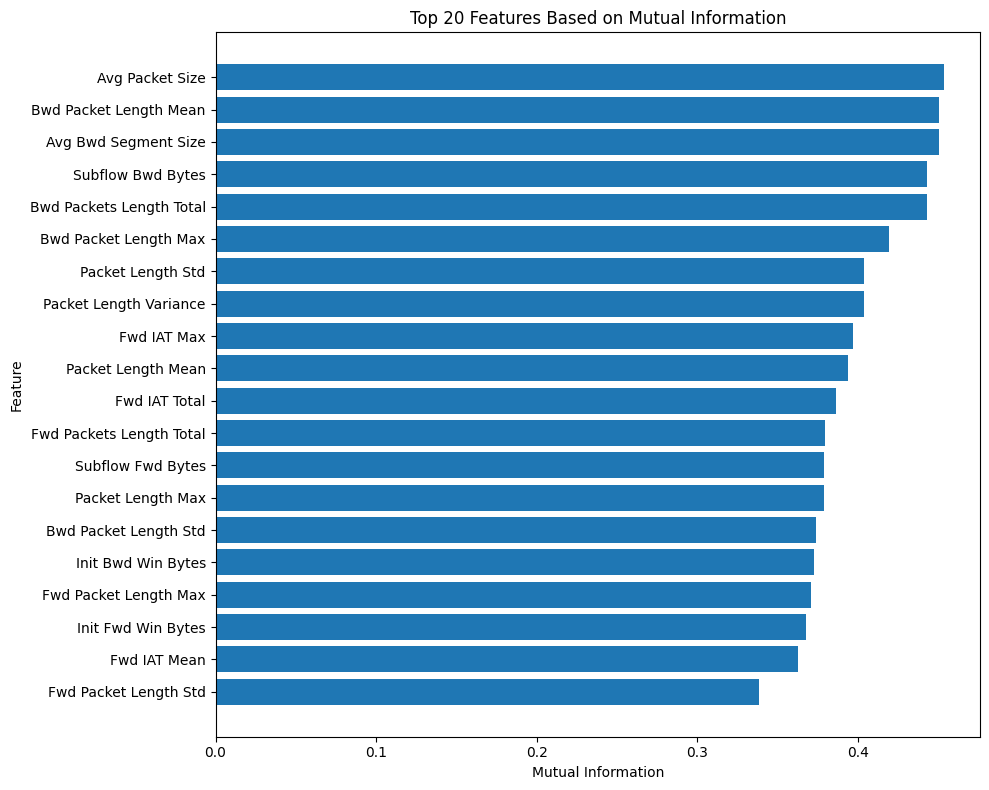

In [23]:
# ============================================================
# 23. VISUALIZE TOP 20 FEATURES
# ============================================================

plot_data = top_20.sort_values(
    "Mutual_Information",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["Feature"],
    plot_data["Mutual_Information"]
)

plt.xlabel("Mutual Information")
plt.ylabel("Feature")
plt.title(
    "Top 20 Features Based on Mutual Information"
)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# 24. FINAL FEATURE LIST
# ============================================================

selected_features = (
    top_20["Feature"]
    .tolist()
)

print("=" * 70)
print("20 FITUR FINAL")
print("=" * 70)

for i, feature in enumerate(
    selected_features,
    start=1
):
    print(f"{i:02d}. {feature}")

20 FITUR FINAL
01. Avg Packet Size
02. Bwd Packet Length Mean
03. Avg Bwd Segment Size
04. Subflow Bwd Bytes
05. Bwd Packets Length Total
06. Bwd Packet Length Max
07. Packet Length Std
08. Packet Length Variance
09. Fwd IAT Max
10. Packet Length Mean
11. Fwd IAT Total
12. Fwd Packets Length Total
13. Subflow Fwd Bytes
14. Packet Length Max
15. Bwd Packet Length Std
16. Init Bwd Win Bytes
17. Fwd Packet Length Max
18. Init Fwd Win Bytes
19. Fwd IAT Mean
20. Fwd Packet Length Std


In [25]:
# ============================================================
# 25. VALIDATE FEATURE SELECTION
# ============================================================

assert len(selected_features) == 20

assert TARGET_COLUMN not in selected_features

assert all(
    feature in X.columns
    for feature in selected_features
)

print("✓ Jumlah fitur = 20")
print("✓ Target tidak masuk sebagai fitur")
print("✓ Semua fitur berasal dari predictor")
print("✓ Feature selection VALID")

✓ Jumlah fitur = 20
✓ Target tidak masuk sebagai fitur
✓ Semua fitur berasal dari predictor
✓ Feature selection VALID


In [26]:
# ============================================================
# 26. CREATE FINAL CLEAN DATASET
# ============================================================

df_final = X[
    selected_features
].copy()

df_final[TARGET_COLUMN] = y

print("Final dataset shape:")
print(df_final.shape)

display(df_final.head())

Final dataset shape:
(1265086, 21)


,Avg Packet Size,Bwd Packet Length Mean,Avg Bwd Segment Size,Subflow Bwd Bytes,Bwd Packets Length Total,Bwd Packet Length Max,Packet Length Std,Packet Length Variance,Fwd IAT Max,Packet Length Mean,...,Fwd Packets Length Total,Subflow Fwd Bytes,Packet Length Max,Bwd Packet Length Std,Init Bwd Win Bytes,Fwd Packet Length Max,Init Fwd Win Bytes,Fwd IAT Mean,Fwd Packet Length Std,Label
0,9.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,4.0,6.000000,...,12.0,12.0,6.0,0.000000,-1.0,6.0,329.0,4.0,0.000000,0
1,9.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,1.0,6.000000,...,12.0,12.0,6.0,0.000000,-1.0,6.0,329.0,1.0,0.000000,0
2,9.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,3.0,6.000000,...,12.0,12.0,6.0,0.000000,-1.0,6.0,245.0,3.0,0.000000,0
3,9.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,1.0,6.000000,...,12.0,12.0,6.0,0.000000,-1.0,6.0,245.0,1.0,0.000000,0
4,81.63636,103.5,103.5,414.0,414.0,207.0,107.527443,11562.151367,460.0,74.833336,...,484.0,484.0,233.0,119.511505,2053.0,233.0,8192.0,101.5,111.967896,0


In [27]:
# ============================================================
# 27. FINAL DATASET VALIDATION
# ============================================================

print("=" * 70)
print("FINAL DATASET VALIDATION")
print("=" * 70)

print("Jumlah baris   :", len(df_final))
print("Jumlah kolom   :", len(df_final.columns))
print("Jumlah fitur   :", len(df_final.columns) - 1)

print("\nMissing values:")
print(
    df_final.isnull().sum().sum()
)

print("\nDuplicate rows:")
print(
    df_final.duplicated().sum()
)

print("\nTarget distribution:")
display(
    df_final[TARGET_COLUMN]
    .value_counts()
)

print("\nData types:")
display(
    df_final.dtypes.value_counts()
)

FINAL DATASET VALIDATION
Jumlah baris   : 1265086
Jumlah kolom   : 21
Jumlah fitur   : 20

Missing values:
0

Duplicate rows:
478110

Target distribution:


Label
0    943316
1    321770
Name: count, dtype: int64


Data types:


float32    20
int64       1
Name: count, dtype: int64

In [28]:
# ============================================================
# 28. SAVE FINAL DATASET
# ============================================================

df_final.to_csv(
    OUTPUT_DATASET,
    index=False
)

print(
    f"Dataset final berhasil disimpan: "
    f"{OUTPUT_DATASET}"
)

Dataset final berhasil disimpan: CIC-IDS2017_20features_clean.csv


In [29]:
# ============================================================
# 29. SAVE FEATURE RANKING
# ============================================================

mi_ranking.to_csv(
    OUTPUT_RANKING,
    index=False
)

print(
    f"Ranking fitur disimpan: "
    f"{OUTPUT_RANKING}"
)

Ranking fitur disimpan: feature_ranking_MI.csv


In [30]:
# ============================================================
# 30. SAVE SELECTED FEATURE LIST
# ============================================================

with open(
    OUTPUT_FEATURES,
    "w"
) as f:

    for feature in selected_features:
        f.write(feature + "\n")

print(
    f"Daftar fitur disimpan: "
    f"{OUTPUT_FEATURES}"
)

Daftar fitur disimpan: selected_20_features.txt


In [31]:
# ============================================================
# 31. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FEATURE SELECTION SELESAI")
print("=" * 70)

print(f"BENIGN data : {len(benign):,}")
print(f"DDoS data   : {len(ddos):,}")
print(f"DoS data    : {len(dos):,}")

print(
    f"\nTotal data setelah concat : "
    f"{len(df_final):,}"
)

print(
    f"Fitur awal                : "
    f"{len(X.columns)}"
)

print(
    f"Fitur final               : "
    f"{len(selected_features)}"
)

print("\n20 fitur final:")

for i, feature in enumerate(
    selected_features,
    start=1
):
    print(f"{i:02d}. {feature}")

print("\nOutput:")
print("1.", OUTPUT_DATASET)
print("2.", OUTPUT_RANKING)
print("3.", OUTPUT_FEATURES)

print("\n✓ Dataset siap digunakan untuk eksperimen imbalance.")



FEATURE SELECTION SELESAI
BENIGN data : 458,831
DDoS data   : 221,264
DoS data    : 584,991

Total data setelah concat : 1,265,086
Fitur awal                : 67
Fitur final               : 20

20 fitur final:
01. Avg Packet Size
02. Bwd Packet Length Mean
03. Avg Bwd Segment Size
04. Subflow Bwd Bytes
05. Bwd Packets Length Total
06. Bwd Packet Length Max
07. Packet Length Std
08. Packet Length Variance
09. Fwd IAT Max
10. Packet Length Mean
11. Fwd IAT Total
12. Fwd Packets Length Total
13. Subflow Fwd Bytes
14. Packet Length Max
15. Bwd Packet Length Std
16. Init Bwd Win Bytes
17. Fwd Packet Length Max
18. Init Fwd Win Bytes
19. Fwd IAT Mean
20. Fwd Packet Length Std

Output:
1. CIC-IDS2017_20features_clean.csv
2. feature_ranking_MI.csv
3. selected_20_features.txt

✓ Dataset siap digunakan untuk eksperimen imbalance.
